## Actividad 1. Cargar y explorar el dataset MNIST

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [16]:
mnist= fetch_openml('mnist_784', version=1, as_frame= False)
x= mnist.data.astype('float32')
y= mnist.target.astype('int32')

print(x.shape)
print(y.shape)
print(x[0].shape)

(70000, 784)
(70000,)
(784,)


[5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7]


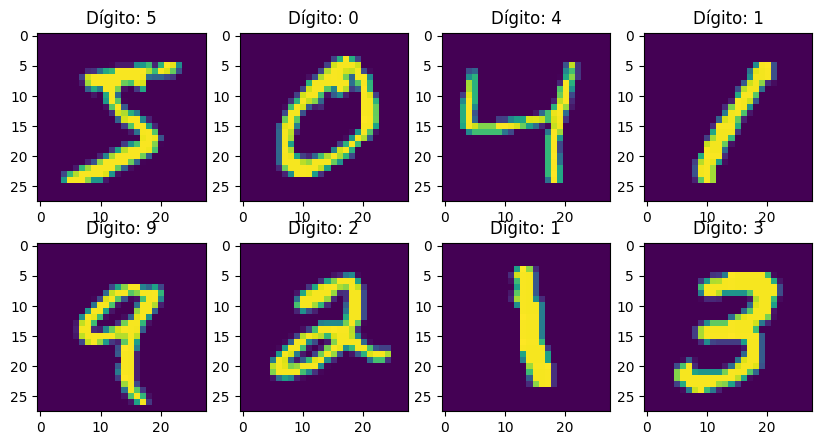

In [17]:
plt.figure(figsize=(10,5))
for i in range(8):
  plt.subplot(2,4,i+1)
  plt.imshow(x[i].reshape(28,28))
  plt.title('Dígito: ' + str(y[i]))

print(y[:16])

## Actividad 2. Preparar las imágenes para los modelos

In [18]:
x=x/255 #NORMALIZAMOS LAS IMÁGENES
x=x.reshape(-1,28,28,1)

print('nueva forma de x: ', x.shape)
print('nueva forma de x: ', x[0].shape)

nueva forma de x:  (70000, 28, 28, 1)
nueva forma de x:  (28, 28, 1)


In [19]:
x_train, x_test, y_train, y_test= train_test_split(x,y,test_size=0.2, random_state=42)
x_train, x_val, y_train, y_val= train_test_split(x_train,y_train,test_size=0.1, random_state=42)

print('entrenamiento:', x_train.shape)
print('validación:', x_val.shape)
print('prueba:', x_test.shape)

entrenamiento: (50400, 28, 28, 1)
validación: (5600, 28, 28, 1)
prueba: (14000, 28, 28, 1)


In [20]:
#KNN y SVM trabajan con las imágenes aplanadas (vectores de 784 valores)
x_train_sub= x_train.reshape(-1,784)[:10000] #10 000 imágenes de entrenamiento para KNN y SVM
y_train_sub= y_train[:10000]
x_val_flat= x_val.reshape(-1,784)
x_test_flat= x_test.reshape(-1,784)

print(x_train_sub.shape)
print(x_val_flat.shape)
print(x_test_flat.shape)

(10000, 784)
(5600, 784)
(14000, 784)


## Actividad 3. Entrenar el modelo K-Vecinos Cercanos (KNN)

In [23]:
model_knn= KNeighborsClassifier(n_neighbors=3)
model_knn.fit(x_train_sub, y_train_sub)

y_pred_val= model_knn.predict(x_val_flat)
print('KNN Accuracy:', accuracy_score(y_val, y_pred_val))

KNN Accuracy: 0.9482142857142857


## Actividad 4. Entrenar el modelo Support Vector Machine (SVM)

In [24]:
model_svm= SVC(kernel='rbf')
model_svm.fit(x_train_sub, y_train_sub)

y_pred_val= model_svm.predict(x_val_flat)
print('SVM accuracy:', accuracy_score(y_val, y_pred_val))

SVM accuracy: 0.9607142857142857


## Actividad 5. Entrenar la Red Neuronal Convolucional (CNN)

In [25]:
#RNA CONVOLUCIONAL
model= tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)), #OJO: Las imágenes ya NO están aplanadas
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(), #reducimos la dimensionalidad del mapa de caraterísticas
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(), #aplanamos nuevamente la imagen para procesarla en capas densas

    #LA PREDICCIÓN FINAL LA TOMAN LAS CAPAS DENSAS
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(36, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [27]:
model.fit(x_train, y_train, epochs=10, validation_data=(x_val, y_val)) #evaluación con el conjunto de validación

Epoch 1/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 31s 19ms/step - accuracy: 0.9902 - loss: 0.0323 - val_accuracy: 0.9846 - val_loss: 0.0616
Epoch 2/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.9910 - loss: 0.0299 - val_accuracy: 0.9834 - val_loss: 0.0597
Epoch 3/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 39s 18ms/step - accuracy: 0.9920 - loss: 0.0256 - val_accuracy: 0.9773 - val_loss: 0.0875
Epoch 4/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9928 - loss: 0.0237 - val_accuracy: 0.9821 - val_loss: 0.0708
Epoch 5/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.9931 - loss: 0.0227 - val_accuracy: 0.9821 - val_loss: 0.0642
Epoch 6/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9936 - loss: 0.0208 - val_accuracy: 0.9836 - val_loss: 0.0702
Epoch 7/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9943 - loss: 0.0198 - val_accuracy: 0.9857 - val_loss: 0.0554
Epoch 8/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9943 -

In [28]:
y_pred_cnn= model.predict(x_test)
print(y_pred_cnn.argmax(1)[:16])
print(y_test[:16])

438/438 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step
[8 4 8 7 7 0 6 2 7 4 3 9 9 8 2 5]
[8 4 8 7 7 0 6 2 7 4 3 9 9 8 2 5]


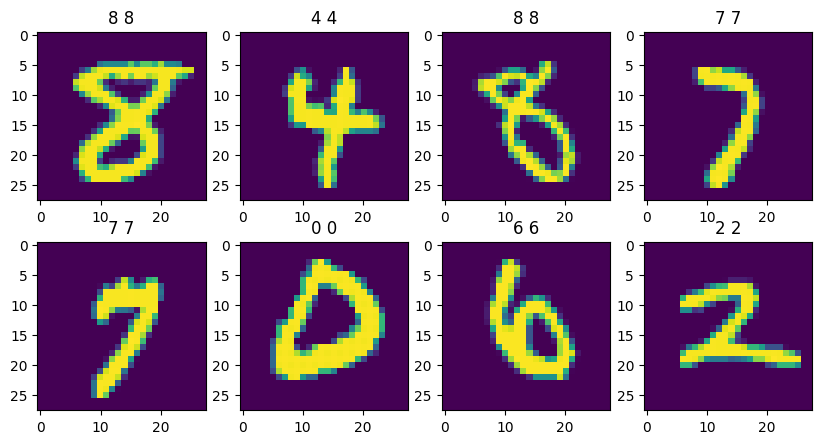

In [29]:
plt.figure(figsize=(10,5))
for i in range(8):
  plt.subplot(2,4,i+1)
  plt.imshow(x_test[i].reshape(28,28))
  plt.title(str(y_test[i])+' '+ str(y_pred_cnn.argmax(1)[i]))

## Actividad 6. Entrenamiento, validación y ajuste de modelos

In [39]:
#KNN: probamos distintos valores de k
for k in [3, 5, 7]:
  knn= KNeighborsClassifier(n_neighbors=k)
  knn.fit(x_train_sub, y_train_sub)
  print('KNN k =', k, '- accuracy en validación:', accuracy_score(y_val, knn.predict(x_val_flat)))

KNN k = 3 - accuracy en validación: 0.9482142857142857
KNN k = 5 - accuracy en validación: 0.9476785714285715
KNN k = 7 - accuracy en validación: 0.9446428571428571


In [40]:
#SVM: probamos distintos kernels
for kernel in ['linear', 'rbf']:
  svm= SVC(kernel=kernel)
  svm.fit(x_train_sub, y_train_sub)
  print('SVM kernel =', kernel, '- accuracy en validación:', accuracy_score(y_val, svm.predict(x_val_flat)))

SVM kernel = linear - accuracy en validación: 0.9083928571428571
SVM kernel = rbf - accuracy en validación: 0.9607142857142857


In [41]:
#SVM: probamos distintos valores de C (kernel rbf)
for c in [10, 100]:
  svm= SVC(kernel='rbf', C=c)
  svm.fit(x_train_sub, y_train_sub)
  print('SVM rbf C =', c, '- accuracy en validación:', accuracy_score(y_val, svm.predict(x_val_flat)))

SVM rbf C = 10 - accuracy en validación: 0.9683928571428572
SVM rbf C = 100 - accuracy en validación: 0.9683928571428572


## 7. Evaluación y comparación de resultados

In [42]:
print('Accuracy KNN:', accuracy_score(y_test, y_pred_knn))
print('Accuracy SVM:', accuracy_score(y_test, y_pred_svm))
print('Accuracy CNN:', accuracy_score(y_test, y_pred_cnn.argmax(1)))

Accuracy KNN: 0.9462857142857143
Accuracy SVM: 0.9652142857142857
Accuracy CNN: 0.9822857142857143


In [43]:
print('KNN')
print(classification_report(y_test, y_pred_knn))

KNN
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      1343
           1       0.91      0.99      0.95      1600
           2       0.97      0.92      0.94      1380
           3       0.94      0.94      0.94      1433
           4       0.95      0.94      0.94      1295
           5       0.93      0.93      0.93      1273
           6       0.97      0.98      0.98      1396
           7       0.95      0.95      0.95      1503
           8       0.98      0.88      0.93      1357
           9       0.92      0.94      0.93      1420

    accuracy                           0.95     14000
   macro avg       0.95      0.95      0.95     14000
weighted avg       0.95      0.95      0.95     14000



In [44]:
print('SVM')
print(classification_report(y_test, y_pred_svm))

SVM
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1343
           1       0.97      0.99      0.98      1600
           2       0.95      0.96      0.96      1380
           3       0.97      0.94      0.96      1433
           4       0.96      0.97      0.96      1295
           5       0.95      0.96      0.96      1273
           6       0.98      0.98      0.98      1396
           7       0.97      0.96      0.97      1503
           8       0.96      0.95      0.96      1357
           9       0.95      0.95      0.95      1420

    accuracy                           0.97     14000
   macro avg       0.97      0.96      0.96     14000
weighted avg       0.97      0.97      0.97     14000



In [45]:
print('CNN')
print(classification_report(y_test, y_pred_cnn.argmax(1)))

CNN
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1343
           1       0.99      0.99      0.99      1600
           2       0.97      0.98      0.98      1380
           3       1.00      0.96      0.98      1433
           4       0.99      0.98      0.99      1295
           5       0.97      0.98      0.98      1273
           6       0.99      0.99      0.99      1396
           7       0.98      0.99      0.98      1503
           8       0.99      0.96      0.98      1357
           9       0.96      0.99      0.98      1420

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000



## El modelo más optimo es **Red Neuronal Convolucional (CNN)**

In [46]:
model_cnn.save('modelo_digitos.h5')
print('Modelo guardado correctamente.')

Modelo guardado correctamente.


In [47]:
from google.colab import files
files.download('modelo_digitos.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>